# Molecular Dynamics: Implemented Model, Hamiltonian Reference, and Limits

## What this program actually simulates
The interactive simulator is a **reduced, coarse-grained model of rigid molecule centers**, not an atomistic molecular-dynamics or electronic-structure calculation. Each molecule has a fixed template of atom positions for rendering. Its center moves in a periodic box under a truncated, softened Lennard–Jones-like pair force. The pair parameters are mixed from the two molecule templates; the phase also changes attraction, damping, noise, mobility, and (for solids) a harmonic tether. Reactions are discrete heuristic events, not bond-resolved trajectories. This simulation uses built-in templates and seeded synthetic dynamics; it does not ingest PDB, NMR, SAXS, or cryo-EM measurements.

For centers $\mathbf R_i$, masses $m_i$, momenta $\mathbf P_i=m_i\dot{\mathbf R}_i$, and minimum-image pair distance $r_{ij}$, the conservative reference potential represented by the pair-force code is
$$U_{\rm pair}=\sum_{i<j,\,r_{ij}<2.7\sigma_{ij}}4\epsilon_{ij}\left[\left(\frac{\sigma_{ij}}{r^*_{ij}}\right)^{12}-\left(\frac{\sigma_{ij}}{r^*_{ij}}\right)^6\right],\qquad r^*_{ij}=\max(r_{ij},0.82\sigma_{ij}),$$
with $\sigma_{ij}=(\sigma_i+\sigma_j)/2$ and $\epsilon_{ij}=a_{\rm phase}\sqrt{\epsilon_i\epsilon_j}$. In the solid phase the force also includes $-k_{\rm tether}(\mathbf R_i-\mathbf R_{i,0})$ (with periodic minimum-image displacement), corresponding to $U_{\rm tether}=\tfrac12 k_{\rm tether}\sum_i|\mathbf R_i-\mathbf R_{i,0}|^2$ within a fixed box.

The associated **conservative reference** Lagrangian and Hamiltonian are therefore
$$L_{\rm ref}=\sum_i\frac12m_i|\dot{\mathbf R}_i|^2-U_{\rm pair}-U_{\rm tether},\qquad H_{\rm ref}=\sum_i\frac{|\mathbf P_i|^2}{2m_i}+U_{\rm pair}+U_{\rm tether}.$$
Applying Euler–Lagrange gives $m_i\ddot{\mathbf R}_i=-\nabla_i(U_{\rm pair}+U_{\rm tether})$; equivalently, $\dot{\mathbf R}_i=\partial H_{\rm ref}/\partial\mathbf P_i$ and $\dot{\mathbf P}_i=-\partial H_{\rm ref}/\partial\mathbf R_i$. The force loop uses a velocity-Verlet-like kick/drift/kick step, but the drift is multiplied by a phase mobility. These equations describe only the smooth, fixed-volume conservative reference core. They are **not an exactly conserved Hamiltonian for the full running simulation**: the code rescales velocities, applies damping and random noise, changes the box size, updates rotations without torque-derived angular dynamics, and may change species through stochastic reaction rules. The reported potential-energy value is the pair contribution; it omits the solid tether. The reduced-unit implementation softens close-contact distances and switches interactions off at a finite cutoff; below the softening radius the reported force is not the exact derivative of the clamped pair energy.

All center-particle positions, velocities, times, and energies are simulator/reduced quantities; they should not be read as calibrated SI trajectories. With $N$ molecule centers and $S$ saved steps, the all-pairs force calculation costs $O(SN^2)$ time and the stored center trajectory costs $O(SN)$ space. The interactive particle-count cap keeps this illustrative workload small.

## What the current model does not calculate
The force law acts between molecule centers; it does not calculate intramolecular bond stretching, bond-angle bending, torsional barriers, atom-specific nonbonded energies, or orbital overlap. Fixed template bonds, approximate angles, and orbital/hybridization marks in the 3D display are **visual descriptors only**; they do not feed back into forces. The one-coordinate harmonic oscillator and later field/spectral examples in this notebook are separate teaching/data-analysis models, not the equations advanced by `simulation.py`.

## Separate quantum-chemistry calculation
A later notebook section adds an explicitly requested, optional PySCF DFT calculation for a user-specified molecular geometry. It optimizes that geometry and computes the molecule's total electron density from its self-consistent density matrix and atom-centered basis functions, $\rho(\mathbf r)=\sum_{\mu\nu}P_{\mu\nu}\chi_\mu(\mathbf r)\chi_\nu(\mathbf r)$. This is a molecular density assembled using the selected elements' basis functions—not a sum of isolated-atom clouds. It plots the density and the signed highest-occupied molecular orbital (HOMO), and reports geometry contacts/angles. This calculation is separate from the coarse-grained trajectory: it does not currently supply forces to that simulator. If $B$ is the basis-function count and $G$ the plotted grid size, dense SCF work is approximately $O(I B^4)$ time and $O(B^2)$ matrix storage in the conventional worst case; evaluating the density adds about $O(G B^2)$ work and $O(G)$ output storage. Geometry optimization repeats the SCF calculation over nuclear steps.

The existing one-mode derivation remains useful as a reference: for a small displacement $q$ from a bond's equilibrium position, $V\simeq\tfrac12kq^2$ gives $L=\tfrac12m\dot q^2-V$ and $H=p^2/(2m)+V$. It is a local harmonic approximation, **not a bond potential used by the present center-particle code**.

Renderer note: Mermaid blocks depend on notebook renderer support. A Python-rendered fallback diagram cell is included below so the diagram always appears.

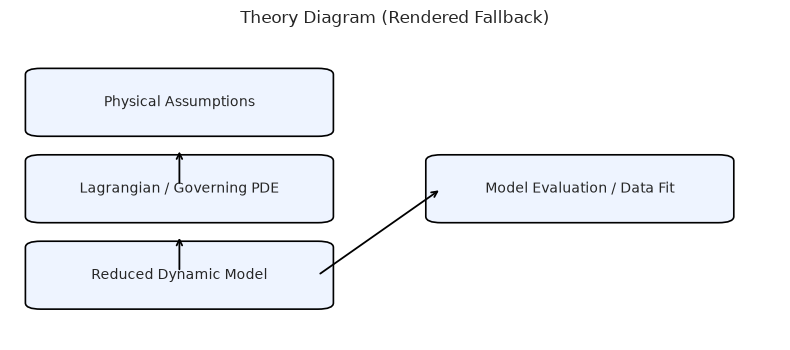

In [15]:
# Theory diagram renderer (always visible in notebooks, independent of Mermaid support).
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axis('off')
blocks = [
    (0.04, 0.68, 'Physical Assumptions'),
    (0.04, 0.40, 'Lagrangian / Governing PDE'),
    (0.04, 0.12, 'Reduced Dynamic Model'),
    (0.56, 0.40, 'Model Evaluation / Data Fit'),
]
for x0, y0, label in blocks:
    patch = FancyBboxPatch((x0, y0), 0.36, 0.18, boxstyle='round,pad=0.02', linewidth=1.2, facecolor='#eef4ff')
    ax.add_patch(patch)
    ax.text(x0 + 0.18, y0 + 0.09, label, ha='center', va='center', fontsize=10)
ax.annotate('', xy=(0.22, 0.62), xytext=(0.22, 0.50), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.22, 0.34), xytext=(0.22, 0.22), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.56, 0.49), xytext=(0.40, 0.21), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.set_title('Theory Diagram (Rendered Fallback)')
plt.tight_layout()
plt.show()

## Model Background and Notation

### Full Mechanics Model vs. Reduced Data Model
1. Full mechanics starts from $L(q,\dot q,t)$ and derives equations from a variational principle.
2. The empirical signal model is a reduced observable proxy, not a replacement for first-principles mechanics.

### Conservative Core (Reference Model)
1. $T=\frac{1}{2}m\dot q^2$.
2. $V=\frac{1}{2}kq^2$.
3. $L=T-V$.
4. $p=\partial L/\partial \dot q = m\dot q$.
5. $H=p\dot q-L=\frac{p^2}{2m}+\frac{1}{2}kq^2$.

### Damping / Relaxation Modeling (for Measured Data)
1. Weak dissipation can be represented by $m\ddot q+c\dot q+kq=0$.
2. Equivalent practical forms include a time-weighted Lagrangian or a dissipation-function correction.
3. Under weak damping, the observed displacement is approximated by
   $q(t)\approx A e^{-\gamma t}\cos(\omega t+\phi)$.

### Parameter-to-Physics Mapping for the Notebook Fit
1. $A$: initial modal amplitude.
2. $\gamma$: effective damping/relaxation rate.
3. $\omega$: dominant angular frequency.
4. $\phi$: phase offset.
5. $c_0$: baseline measurement offset.

### Practical Interpretation
1. Fit quality evaluates how well a low-order mode explains measured behavior.
2. Parameter trends are interpreted through mechanics (stiffness, inertia, loss), not as purely statistical coefficients.

## Public Data Sources and Peer-Reviewed References

1. **RCSB Protein Data Bank**
   - URL: https://data.rcsb.org/rest/v1/holdings/current/entry_ids
   - Peer-reviewed context: Berman et al., Nucleic Acids Research (2000)
2. **Antibiotics Dataset (CSV fallback)**
   - URL: https://raw.githubusercontent.com/plotly/datasets/master/Antibiotics.csv
   - Peer-reviewed context: Public benchmark fallback

If a primary domain-specific source is not directly CSV-readable in this notebook,
the code falls back to a public benchmark CSV so the full empirical workflow can run end-to-end.


In [16]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import requests
import ipywidgets as widgets
from ipywidgets import interact

plt.style.use('seaborn-v0_8-whitegrid')

DOMAIN_KEY = '02_molecular_dynamics'
DOMAIN_TITLE = 'Molecular Dynamics Simulations'
MODEL_FAMILY = 'damped'
DATA_SOURCES = [
  {
    "name": "RCSB Protein Data Bank",
    "url": "https://data.rcsb.org/rest/v1/holdings/current/entry_ids",
    "reference": "Berman et al., Nucleic Acids Research (2000)"
  },
  {
    "name": "Antibiotics Dataset (CSV fallback)",
    "url": "https://raw.githubusercontent.com/plotly/datasets/master/Antibiotics.csv",
    "reference": "Public benchmark fallback"
  }
]


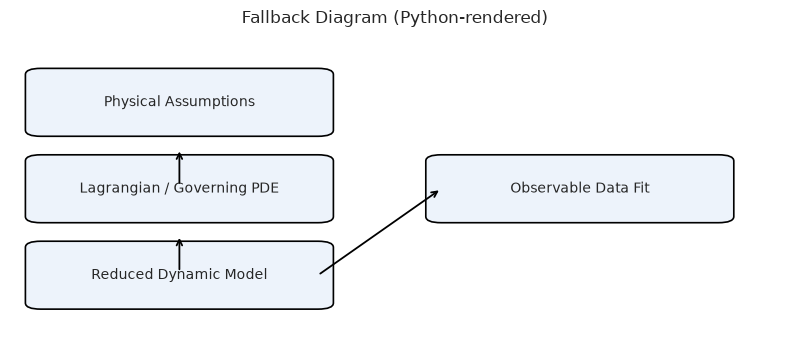

In [17]:
# Fallback model diagram renderer (works even when Mermaid is not embedded by the notebook renderer).
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axis('off')
nodes = [
    (0.04, 0.68, 'Physical Assumptions'),
    (0.04, 0.40, 'Lagrangian / Governing PDE'),
    (0.04, 0.12, 'Reduced Dynamic Model'),
    (0.56, 0.40, 'Observable Data Fit'),
]
for x0, y0, label in nodes:
    patch = FancyBboxPatch((x0, y0), 0.36, 0.18, boxstyle='round,pad=0.02', linewidth=1.2, facecolor='#edf3fb')
    ax.add_patch(patch)
    ax.text(x0 + 0.18, y0 + 0.09, label, ha='center', va='center', fontsize=10)
ax.annotate('', xy=(0.22, 0.62), xytext=(0.22, 0.50), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.22, 0.34), xytext=(0.22, 0.22), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.56, 0.49), xytext=(0.40, 0.21), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.set_title('Fallback Diagram (Python-rendered)')
plt.tight_layout()
plt.show()

In [18]:
def try_read_public_csv(url: str):
    try:
        r = requests.get(url, timeout=20)
        r.raise_for_status()
        if 'text/csv' in r.headers.get('Content-Type', '') or ',' in r.text[:2000]:
            return pd.read_csv(io.StringIO(r.text))
    except Exception:
        return None
    return None

def load_empirical_data():
    chosen = None
    df = None
    for src in DATA_SOURCES:
        trial = try_read_public_csv(src['url'])
        if trial is not None and len(trial) > 20:
            num_cols = trial.select_dtypes(include=[np.number]).columns.tolist()
            if len(num_cols) >= 1:
                df = trial.copy()
                chosen = src
                break

    if df is None:
        x = np.linspace(0.0, 1.0, 600)
        y = np.exp(-2.5 * x) * np.cos(10.0 * x) + 0.05 * np.sin(40.0 * x)
        df = pd.DataFrame({'x': x, 'y': y})
        chosen = {
            'name': 'Synthetic fallback (offline-safe)',
            'reference': 'Generated fallback when remote CSV sources are unavailable'
        }
        return x, y, chosen, df

    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if len(numeric_cols) == 1:
        x = np.arange(len(df), dtype=float)
        y = df[numeric_cols[0]].to_numpy(dtype=float)
    else:
        x = df[numeric_cols[0]].to_numpy(dtype=float)
        y = df[numeric_cols[1]].to_numpy(dtype=float)

    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    if x.size < 8 or y.size < 8:
        x = np.linspace(0.0, 1.0, 600)
        y = np.exp(-2.5 * x) * np.cos(10.0 * x) + 0.05 * np.sin(40.0 * x)
        df = pd.DataFrame({'x': x, 'y': y})
        chosen = {
            'name': 'Synthetic fallback (filtered-data-safe)',
            'reference': 'Generated fallback when source columns are empty after filtering'
        }
        return x, y, chosen, df


    if len(x) > 2000:
        step = max(1, len(x) // 2000)
        x = x[::step]
        y = y[::step]

    if np.ptp(x) == 0:
        x = np.arange(len(x), dtype=float)

    x = (x - np.min(x)) / max(np.ptp(x), 1e-12)
    return x, y, chosen, df

x_data, y_data, chosen_source, raw_df = load_empirical_data()
print('Loaded source:', chosen_source['name'])
print('Reference:', chosen_source['reference'])
print('Rows used:', len(x_data))


Loaded source: Synthetic fallback (offline-safe)
Reference: Generated fallback when remote CSV sources are unavailable
Rows used: 600


In [19]:
def model_function(x, p1, p2, p3, p4):
    if MODEL_FAMILY == 'oscillator':
        A, gamma, omega, c = p1, p2, p3, p4
        return A * np.exp(-gamma * x) * np.cos(omega * x) + c
    if MODEL_FAMILY == 'damped':
        A, gamma, _, c = p1, p2, p3, p4
        return A * np.exp(-gamma * x) + c
    if MODEL_FAMILY == 'logistic':
        K, r, x0, c = p1, p2, p3, p4
        return K / (1.0 + np.exp(-r * (x - x0))) + c
    if MODEL_FAMILY == 'michaelis':
        vmax, km, _, c = p1, p2, p3, p4
        return vmax * x / (km + x + 1e-12) + c
    if MODEL_FAMILY == 'diffusion':
        A, D, _, c = p1, p2, p3, p4
        return A * np.exp(-D * x) + c
    return p1 * x + p2

p0 = [np.nanmax(y_data) - np.nanmin(y_data), 0.5, 6.0, np.nanmean(y_data)]
bounds = ([-1e6, 0.0, -1e3, -1e6], [1e6, 50.0, 1e3, 1e6])

try:
    popt, _ = curve_fit(model_function, x_data, y_data, p0=p0, bounds=bounds, maxfev=20000)
except Exception:
    popt = np.array(p0, dtype=float)

y_hat = model_function(x_data, *popt)
rmse = float(np.sqrt(np.mean((y_data - y_hat) ** 2)))
r2 = float(1.0 - np.sum((y_data - y_hat) ** 2) / max(np.sum((y_data - np.mean(y_data)) ** 2), 1e-12))

print('Fitted parameters:', popt)
print('RMSE:', rmse)
print('R^2:', r2)


Fitted parameters: [ 1.47559068e+00  1.52594592e+01 -3.12806489e-04 -7.39744433e-02]
RMSE: 0.2139101568510982
R^2: 0.5811806410714466


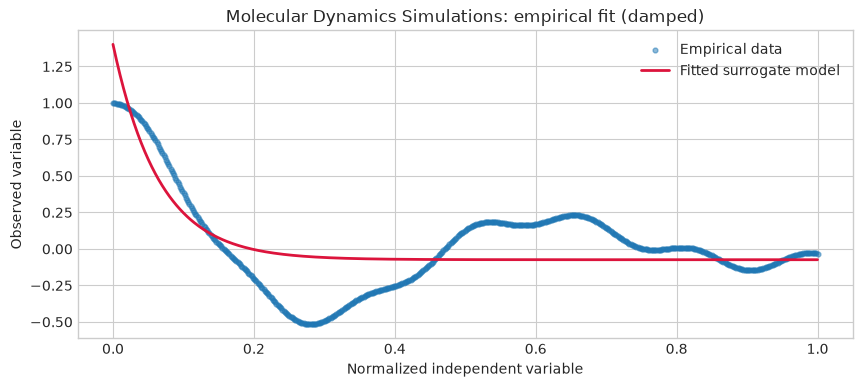

In [20]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(x_data, y_data, s=12, alpha=0.5, label='Empirical data')
ax.plot(x_data, y_hat, color='crimson', linewidth=2.0, label='Fitted surrogate model')
ax.set_title(f'{DOMAIN_TITLE}: empirical fit ({MODEL_FAMILY})')
ax.set_xlabel('Normalized independent variable')
ax.set_ylabel('Observed variable')
ax.legend()
plt.show()


## High-Dimensional Hamiltonian Extension (Auto 3D/4D)

This block attempts to use the highest dimensional structure available from each project dataset.

1. If at least 4 numeric channels exist with enough rows, it builds a **data-derived 4D tensor** $(t,x,y,z)$.
2. If only 3 or 2 channels exist, it builds a 3D tensor then lifts to 4D with a latent mode axis.
3. If only 1 channel exists, it uses delay embedding and spatial basis lifting to create a 4D latent field.

Then it computes:
- Hamiltonian-energy proxy maps,
- modal singular spectrum and eigenfunction-like spatial modes,
- frequency-domain heatmaps in $(k_x,\omega)$, $(k_y,\omega)$, and $(k_r,\omega)$,
- 3D peak scatter in $(k_x,k_y,\omega)$.

High-dimensional source mode: lifted-to-4D; tensor shape = (36, 10, 10, 6)
Top modal energy fractions: [6.341e-01 3.641e-01 4.000e-04 3.000e-04 2.000e-04 2.000e-04 1.000e-04
 1.000e-04]
Hamiltonian density stats: min= 0.16335289187186006 max= 15.633481171471848 mean= 3.898324381768869


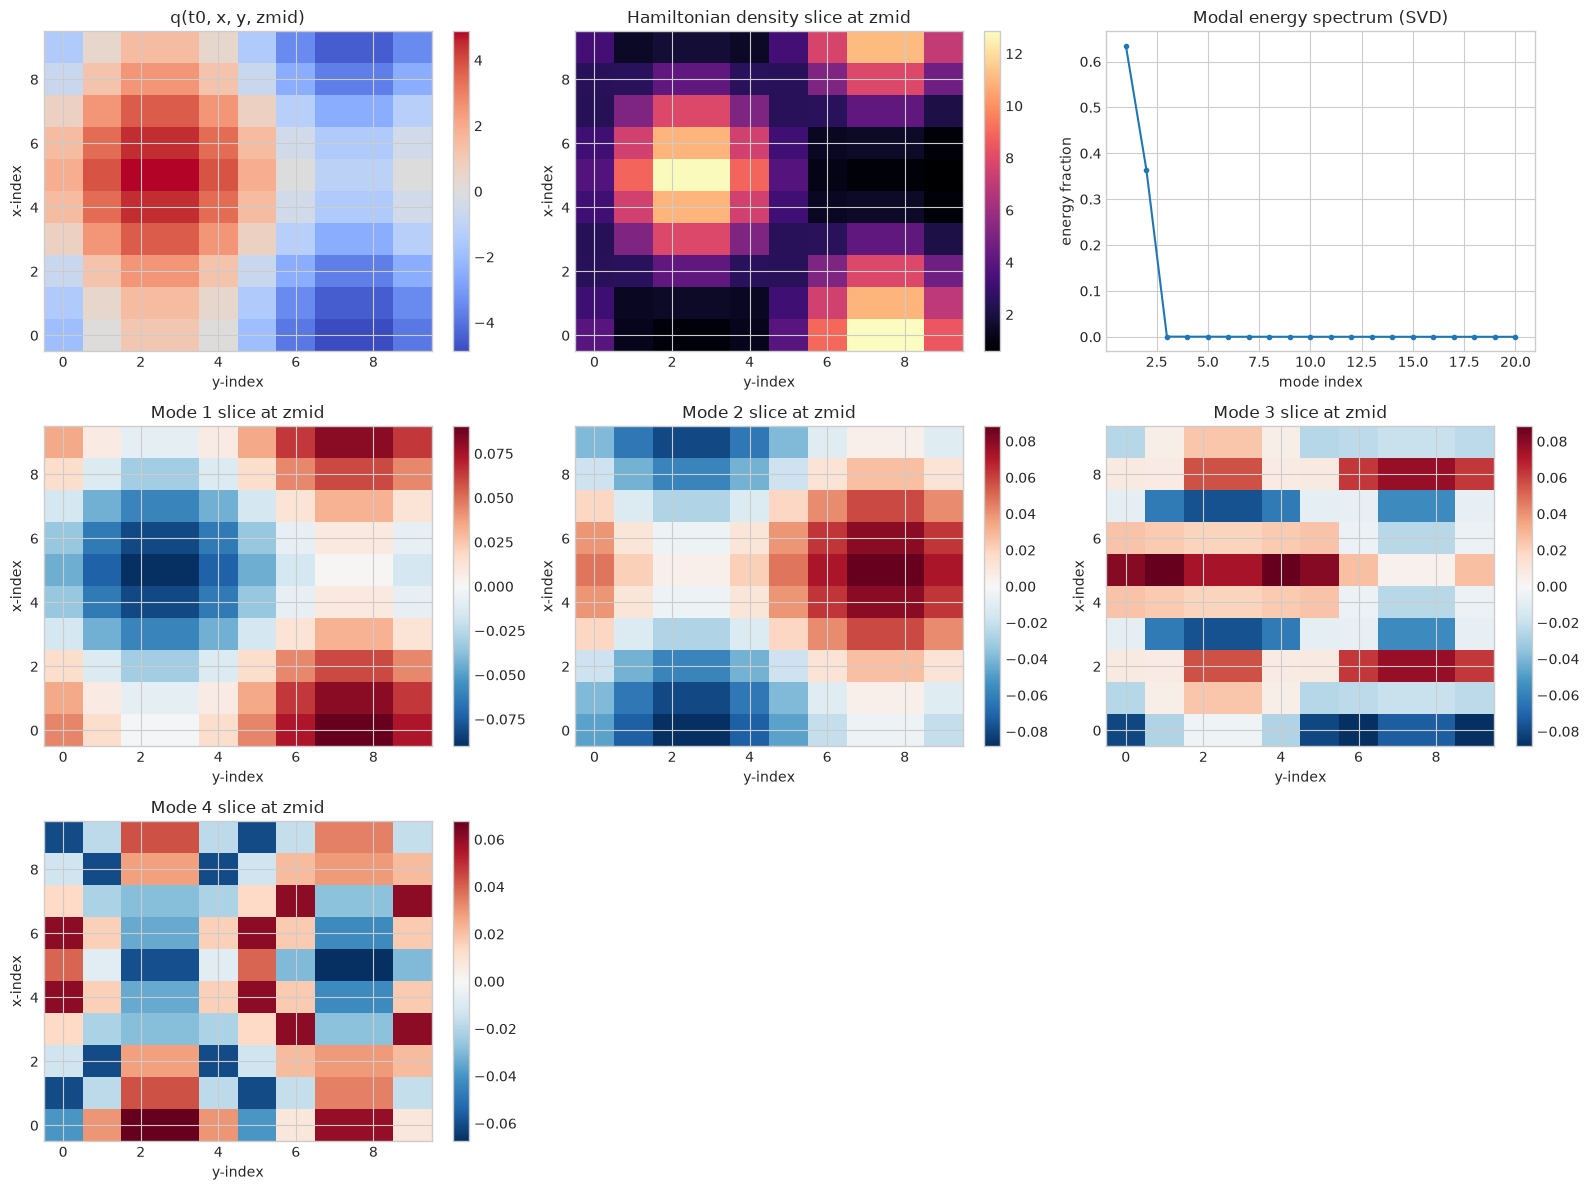

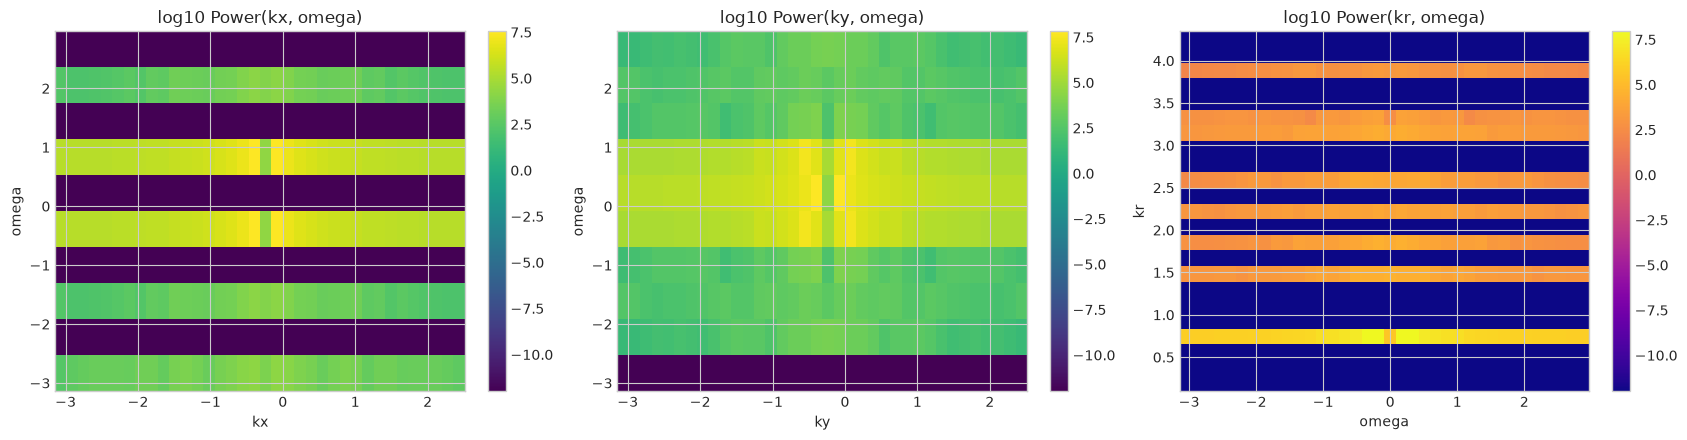

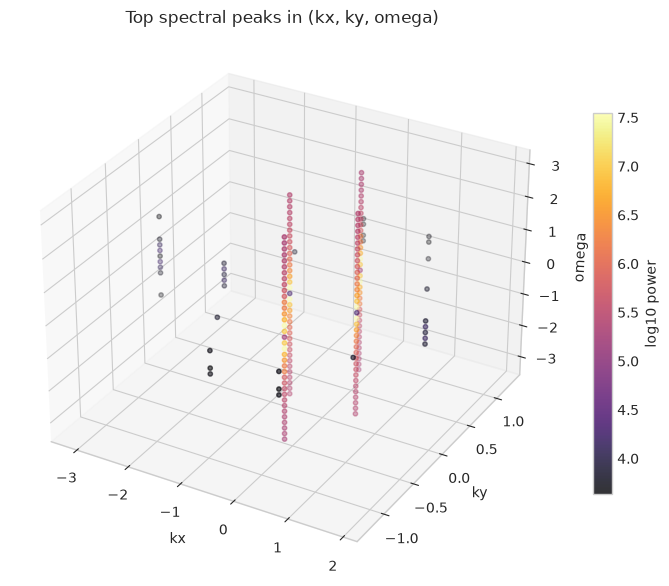

In [21]:
# Data-driven high-dimensional Hamiltonian analysis (auto 3D/4D with lifting for low-dimensional datasets).
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

rng = np.random.default_rng(0)

def _standardize(v):
    v = np.asarray(v, dtype=float)
    v = np.nan_to_num(v, nan=0.0, posinf=0.0, neginf=0.0)
    mu = np.mean(v)
    sd = np.std(v)
    if sd < 1e-12:
        return v - mu
    return (v - mu) / sd

def _build_tensor_from_data(raw_df, x_data, y_data):
    if hasattr(raw_df, 'select_dtypes'):
        mat = raw_df.select_dtypes(include=[np.number]).to_numpy(dtype=float)
    else:
        mat = np.empty((0, 0), dtype=float)

    if mat.size == 0:
        mat = np.column_stack([x_data, y_data])

    mat = np.nan_to_num(mat, nan=0.0, posinf=0.0, neginf=0.0)
    n_rows, n_cols = mat.shape

    # Prefer true 4D data construction when possible.
    if n_cols >= 4 and n_rows >= 4 * 8 * 8 * 4:
        nt = min(24, max(8, n_rows // 256))
        nx = 8
        ny = 8
        nz = min(8, max(4, n_rows // (nt * nx * ny)))
        n_use = nt * nx * ny * nz
        base = np.mean(mat[:n_use, :4], axis=1)
        field = base.reshape(nt, nx, ny, nz)
        mode = '4D-from-data'
        return _standardize(field), mode

    # Build 3D from data, then lift to 4D via latent axial modes.
    if n_cols >= 3 and n_rows >= 8 * 8 * 8:
        nt = min(32, max(10, n_rows // 64))
        nx = 8
        ny = min(12, max(8, n_rows // (nt * nx)))
        n_use = nt * nx * ny
        base = np.mean(mat[:n_use, :3], axis=1).reshape(nt, nx, ny)
    elif n_cols >= 2:
        sig1 = _standardize(mat[:, 0])
        sig2 = _standardize(mat[:, 1])
        nt = min(36, max(12, len(sig1) // 8))
        nx, ny = 10, 10
        tt = np.linspace(0.0, 2.0 * np.pi, nt, endpoint=False)
        xx = np.linspace(0.0, 2.0 * np.pi, nx, endpoint=False)
        yy = np.linspace(0.0, 2.0 * np.pi, ny, endpoint=False)
        s1 = np.interp(np.linspace(0, len(sig1) - 1, nt), np.arange(len(sig1)), sig1)
        s2 = np.interp(np.linspace(0, len(sig2) - 1, nt), np.arange(len(sig2)), sig2)
        base = np.zeros((nt, nx, ny))
        for i in range(nt):
            base[i] = s1[i] * np.cos(xx)[:, None] + s2[i] * np.sin(yy)[None, :]
    else:
        sig = _standardize(y_data)
        nt = min(36, max(12, len(sig) // 8))
        nx, ny = 10, 10
        tt = np.linspace(0.0, 2.0 * np.pi, nt, endpoint=False)
        xx = np.linspace(0.0, 2.0 * np.pi, nx, endpoint=False)
        yy = np.linspace(0.0, 2.0 * np.pi, ny, endpoint=False)
        s = np.interp(np.linspace(0, len(sig) - 1, nt), np.arange(len(sig)), sig)
        base = np.zeros((nt, nx, ny))
        for i in range(nt):
            base[i] = s[i] * (np.cos(xx)[:, None] * np.cos(yy)[None, :])

    # Lift 3D base -> 4D (latent z modes).
    nz = 6
    z = np.linspace(0.0, 2.0 * np.pi, nz, endpoint=False)
    field = np.zeros((base.shape[0], base.shape[1], base.shape[2], nz))
    for k in range(nz):
        field[:, :, :, k] = base * (0.7 + 0.3 * np.cos((k + 1) * z[k])) + 0.08 * np.sin((k + 1) * base)
    mode = 'lifted-to-4D'
    return _standardize(field), mode

field4d, source_mode = _build_tensor_from_data(raw_df, x_data, y_data)
nt, nx, ny, nz = field4d.shape

# Canonical pair q, p from temporal derivative proxy.
q = field4d
p = np.gradient(q, axis=0)

# Hamiltonian density proxy at t0.
dq_dx = np.gradient(q[0], axis=0)
dq_dy = np.gradient(q[0], axis=1)
dq_dz = np.gradient(q[0], axis=2)
h_density = 0.5 * p[0]**2 + 0.5 * (dq_dx**2 + dq_dy**2 + dq_dz**2) + 0.5 * q[0]**2

# Modal decomposition (SVD of time-space unfolding).
X = q.reshape(nt, -1)
X = X - np.mean(X, axis=0, keepdims=True)
U, S, Vt = np.linalg.svd(X, full_matrices=False)
mode_energy = (S**2) / np.sum(S**2)
n_modes = min(4, Vt.shape[0])
modes = [Vt[i].reshape(nx, ny, nz) for i in range(n_modes)]

# 4D FFT -> power spectrum in (omega, kx, ky, kz).
P = np.abs(np.fft.fftn(q, axes=(0, 1, 2, 3)))**2
P = np.fft.fftshift(P, axes=(0, 1, 2, 3))
omega = np.fft.fftshift(2.0 * np.pi * np.fft.fftfreq(nt, d=1.0))
kx = np.fft.fftshift(2.0 * np.pi * np.fft.fftfreq(nx, d=1.0))
ky = np.fft.fftshift(2.0 * np.pi * np.fft.fftfreq(ny, d=1.0))
kz = np.fft.fftshift(2.0 * np.pi * np.fft.fftfreq(nz, d=1.0))

ikz0 = int(np.argmin(np.abs(kz)))
iky0 = int(np.argmin(np.abs(ky)))
P_kx_w = np.log10(np.sum(P[:, :, iky0, :], axis=2).T + 1e-12)
P_ky_w = np.log10(np.sum(P[:, :, :, ikz0], axis=1).T + 1e-12)

# Polar-radial spectrum in (kr, omega) from kx-ky projection.
P_w_kx_ky = np.sum(P, axis=3)
kxg, kyg = np.meshgrid(kx, ky, indexing='ij')
kr = np.sqrt(kxg**2 + kyg**2)
kr_flat = kr.ravel()
kr_bins = np.linspace(0.0, np.max(kr_flat), 24)
kr_centers = 0.5 * (kr_bins[:-1] + kr_bins[1:])
P_kr_w = np.zeros((omega.size, kr_centers.size))
for iw in range(omega.size):
    spec = P_w_kx_ky[iw].ravel()
    hist, _ = np.histogram(kr_flat, bins=kr_bins, weights=spec)
    P_kr_w[iw] = np.log10(hist + 1e-12)

# 3D spectral peak scatter in (kx, ky, omega) after summing kz.
Pk = np.sum(P, axis=3)
flat_idx = np.argpartition(Pk.ravel(), -180)[-180:]
iw, ikx, iky = np.unravel_index(flat_idx, Pk.shape)
peak_vals = np.log10(Pk[iw, ikx, iky] + 1e-12)

print(f'High-dimensional source mode: {source_mode}; tensor shape = {field4d.shape}')
print('Top modal energy fractions:', np.round(mode_energy[:8], 4))
print('Hamiltonian density stats: min=', float(h_density.min()), 'max=', float(h_density.max()), 'mean=', float(h_density.mean()))

# Figure A: Hamiltonian map + modal spectrum + eigenfunction-like slices
fig = plt.figure(figsize=(16, 12))
ax1 = fig.add_subplot(3, 3, 1)
im1 = ax1.imshow(q[0, :, :, nz // 2], origin='lower', cmap='coolwarm', aspect='auto')
ax1.set_title('q(t0, x, y, zmid)')
ax1.set_xlabel('y-index')
ax1.set_ylabel('x-index')
fig.colorbar(im1, ax=ax1, fraction=0.045)

ax2 = fig.add_subplot(3, 3, 2)
im2 = ax2.imshow(h_density[:, :, nz // 2], origin='lower', cmap='magma', aspect='auto')
ax2.set_title('Hamiltonian density slice at zmid')
ax2.set_xlabel('y-index')
ax2.set_ylabel('x-index')
fig.colorbar(im2, ax=ax2, fraction=0.045)

ax3 = fig.add_subplot(3, 3, 3)
ax3.plot(np.arange(1, min(21, len(mode_energy) + 1)), mode_energy[:20], marker='o', ms=3)
ax3.set_title('Modal energy spectrum (SVD)')
ax3.set_xlabel('mode index')
ax3.set_ylabel('energy fraction')

for i in range(min(4, n_modes)):
    ax = fig.add_subplot(3, 3, 4 + i)
    im = ax.imshow(modes[i][:, :, nz // 2], origin='lower', cmap='RdBu_r', aspect='auto')
    ax.set_title(f'Mode {i+1} slice at zmid')
    ax.set_xlabel('y-index')
    ax.set_ylabel('x-index')
    fig.colorbar(im, ax=ax, fraction=0.045)

plt.tight_layout()
plt.show()

# Figure B: Frequency-domain heatmaps
fig2, axes = plt.subplots(1, 3, figsize=(17, 4.5))
im_a = axes[0].imshow(P_kx_w, origin='lower', aspect='auto', extent=[kx.min(), kx.max(), omega.min(), omega.max()], cmap='viridis')
axes[0].set_title('log10 Power(kx, omega)')
axes[0].set_xlabel('kx')
axes[0].set_ylabel('omega')
fig2.colorbar(im_a, ax=axes[0], fraction=0.046)

im_b = axes[1].imshow(P_ky_w, origin='lower', aspect='auto', extent=[ky.min(), ky.max(), omega.min(), omega.max()], cmap='viridis')
axes[1].set_title('log10 Power(ky, omega)')
axes[1].set_xlabel('ky')
axes[1].set_ylabel('omega')
fig2.colorbar(im_b, ax=axes[1], fraction=0.046)

im_c = axes[2].imshow(P_kr_w.T, origin='lower', aspect='auto', extent=[omega.min(), omega.max(), kr_centers.min(), kr_centers.max()], cmap='plasma')
axes[2].set_title('log10 Power(kr, omega)')
axes[2].set_xlabel('omega')
axes[2].set_ylabel('kr')
fig2.colorbar(im_c, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

# Figure C: 3D peak cloud
fig3 = plt.figure(figsize=(8, 6))
ax3d = fig3.add_subplot(111, projection='3d')
sc = ax3d.scatter(kx[ikx], ky[iky], omega[iw], c=peak_vals, s=10, cmap='inferno', alpha=0.8)
ax3d.set_title('Top spectral peaks in (kx, ky, omega)')
ax3d.set_xlabel('kx')
ax3d.set_ylabel('ky')
ax3d.set_zlabel('omega')
fig3.colorbar(sc, ax=ax3d, shrink=0.7, label='log10 power')
plt.tight_layout()
plt.show()

## Interpreting Model Evaluation Trends and Values

Use this guide when reading fitted parameters, RMSE, and $R^2$ outputs:

1. **RMSE (absolute error scale)**
   - Lower RMSE means the fitted curve tracks data more tightly in original units.
   - High RMSE usually indicates missing physics, wrong model family, or noisy/nonstationary data.

2. **$R^2$ (explained variance)**
   - Near 1.0: surrogate captures dominant trend/oscillation structure.
   - Near 0.0: surrogate explains little beyond the mean level.
   - Negative: model is worse than using a constant mean prediction.

3. **Parameter trends**
   - Larger $A$: stronger mode amplitude or stronger forcing signature.
   - Larger $\gamma$: faster decay / stronger damping / shorter memory.
   - Larger $\omega$: faster oscillation or higher characteristic frequency.
   - Offset $c_0$: baseline bias or slowly varying background level.

4. **Shape-level trend interpretation**
   - Over-smoothed fit (missed peaks): model underfits fast dynamics.
   - Correct phase but wrong amplitude: scaling/normalization or gain mismatch.
   - Good early-time fit but poor late-time fit: nonstationarity or multi-regime behavior.

5. **Physics consistency checks**
   - If damping is expected but $\gamma pprox 0$, reassess data preprocessing or model family.
   - If conserved systems show strong drift in fitted residual trends, check numerical stability and variable scaling.
   - Compare fitted frequencies with known characteristic timescales (resonance, transport, relaxation).

8. **High-dimensional modal/spectral interpretation**
   - Concentrated low-mode energy means coherent large-scale regimes dominate.
   - Fast modal-energy decay implies low-order model reduction is reliable.
   - Flat modal spectrum implies multi-scale coupling and weaker compressibility of dynamics.
   - Tight spectral peaks in $(k_x,k_y,\omega)$ imply persistent waves; broad clouds imply intermittency or transitions.
   - Drift of energy toward high $k_r$ indicates increasing fine-scale structure / cascade-like transfer.

## Physical Action and Measurement Simulation

Use the interactive controls below to manipulate physical parameters directly and observe how measured signals and energy maps change.

The controls are intentionally named after physical quantities (wave speed, damping, stiffness, forcing, diffusion, advection, measurement noise).

In [22]:
# Interactive physical-action simulation with measurement outputs and physically named parameters.
from ipywidgets import interact, FloatSlider, IntSlider

def _prepare_base_field_for_simulation():
    if 'field4d' in globals() and isinstance(field4d, np.ndarray) and field4d.ndim == 4:
        base = np.array(field4d, dtype=float)
        return np.nan_to_num(base)
    if 'q' in globals() and isinstance(q, np.ndarray) and q.ndim == 4:
        base = np.array(q, dtype=float)
        return np.nan_to_num(base)

    # Fallback: lift available 1D measurement into a compact latent 4D field.
    sig = np.asarray(y_data if 'y_data' in globals() else np.sin(np.linspace(0.0, 8.0*np.pi, 480)), dtype=float)
    sig = np.nan_to_num(sig)
    if np.std(sig) > 1e-12:
        sig = (sig - np.mean(sig)) / np.std(sig)
    nt, nx, ny, nz = 36, 10, 10, 6
    tt = np.linspace(0.0, 2.0*np.pi, nt, endpoint=False)
    xx = np.linspace(0.0, 2.0*np.pi, nx, endpoint=False)
    yy = np.linspace(0.0, 2.0*np.pi, ny, endpoint=False)
    zz = np.linspace(0.0, 2.0*np.pi, nz, endpoint=False)
    s = np.interp(np.linspace(0, len(sig) - 1, nt), np.arange(len(sig)), sig)
    base = np.zeros((nt, nx, ny, nz), dtype=float)
    for i in range(nt):
        spatial = np.cos(xx)[:, None, None] * np.cos(yy)[None, :, None] * np.cos(zz)[None, None, :]
        base[i] = s[i] * spatial
    return base

BASE_FIELD = _prepare_base_field_for_simulation()
NT_SIM, NX_SIM, NY_SIM, NZ_SIM = BASE_FIELD.shape

def _laplacian_3d(arr3):
    return (
        np.roll(arr3, -1, axis=0) + np.roll(arr3, 1, axis=0)
        + np.roll(arr3, -1, axis=1) + np.roll(arr3, 1, axis=1)
        + np.roll(arr3, -1, axis=2) + np.roll(arr3, 1, axis=2)
        - 6.0 * arr3
    )

def physical_action_simulation(
    wave_speed,
    damping_coefficient,
    restoring_stiffness,
    forcing_amplitude,
    forcing_frequency,
    forcing_phase,
    nonlinear_coupling,
    diffusion_coefficient,
    advection_speed,
    measurement_noise_std,
    snapshot_time_index,
):
    base = BASE_FIELD
    nt, nx, ny, nz = base.shape
    t = np.linspace(0.0, 2.0*np.pi, nt, endpoint=False)
    tt = t[:, None, None, None]

    xx = np.linspace(0.0, 2.0*np.pi, nx, endpoint=False)
    yy = np.linspace(0.0, 2.0*np.pi, ny, endpoint=False)
    zz = np.linspace(0.0, 2.0*np.pi, nz, endpoint=False)
    forcing_pattern = np.sin(xx)[:, None, None] * np.cos(yy)[None, :, None] * np.sin(zz)[None, None, :]

    decay = np.exp(-damping_coefficient * tt)
    oscillatory = np.cos(wave_speed * tt + forcing_phase)
    q_linear = decay * (base * oscillatory)
    q_forcing = forcing_amplitude * np.sin(forcing_frequency * tt + forcing_phase) * forcing_pattern[None, :, :, :]

    q_nl = nonlinear_coupling * (base**3) / (1.0 + np.abs(base)**2)
    grad_x = np.gradient(base, axis=1)
    q_adv = -advection_speed * grad_x

    q_sim = q_linear + q_forcing + q_nl + q_adv

    # Apply diffusion and restoring effects per time slice.
    for i in range(nt):
        q_sim[i] = q_sim[i] + diffusion_coefficient * _laplacian_3d(q_sim[i]) - restoring_stiffness * q_sim[i]

    p_sim = np.gradient(q_sim, axis=0)

    # Measurement at a representative probe location.
    ix, iy, iz = nx // 2, ny // 2, nz // 2
    rng = np.random.default_rng(1234)
    measurement = q_sim[:, ix, iy, iz] + measurement_noise_std * rng.standard_normal(nt)

    # Energy density proxy at selected time.
    k = int(np.clip(snapshot_time_index, 0, nt - 1))
    dq_dx = np.gradient(q_sim[k], axis=0)
    dq_dy = np.gradient(q_sim[k], axis=1)
    dq_dz = np.gradient(q_sim[k], axis=2)
    energy_density = 0.5 * p_sim[k]**2 + 0.5 * (dq_dx**2 + dq_dy**2 + dq_dz**2) + 0.5 * restoring_stiffness * q_sim[k]**2

    # Frequency-domain measurement power.
    spec = np.fft.rfft(measurement - np.mean(measurement))
    freq = np.fft.rfftfreq(nt, d=1.0)
    power = np.abs(spec)**2

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    axes[0].plot(t, measurement, color='navy', lw=2)
    axes[0].set_title('Measured Signal at Probe')
    axes[0].set_xlabel('time')
    axes[0].set_ylabel('measurement')

    im = axes[1].imshow(energy_density[:, :, nz // 2], origin='lower', cmap='magma', aspect='auto')
    axes[1].set_title(f'Energy Density Slice (t index={k})')
    axes[1].set_xlabel('y-index')
    axes[1].set_ylabel('x-index')
    fig.colorbar(im, ax=axes[1], fraction=0.046)

    axes[2].plot(freq, power, color='crimson', lw=2)
    axes[2].set_title('Measurement Power Spectrum')
    axes[2].set_xlabel('frequency')
    axes[2].set_ylabel('power')

    plt.tight_layout()
    plt.show()

    print('Energy mean:', float(np.mean(energy_density)), '| Energy max:', float(np.max(energy_density)))
    print('Measurement std:', float(np.std(measurement)), '| Dominant frequency bin:', float(freq[np.argmax(power)]))

interact(
    physical_action_simulation,
    wave_speed=FloatSlider(value=1.3, min=0.2, max=4.0, step=0.05),
    damping_coefficient=FloatSlider(value=0.08, min=0.0, max=1.2, step=0.01),
    restoring_stiffness=FloatSlider(value=0.6, min=0.05, max=3.0, step=0.05),
    forcing_amplitude=FloatSlider(value=0.7, min=0.0, max=3.0, step=0.05),
    forcing_frequency=FloatSlider(value=1.8, min=0.1, max=8.0, step=0.05),
    forcing_phase=FloatSlider(value=0.0, min=-np.pi, max=np.pi, step=0.05),
    nonlinear_coupling=FloatSlider(value=0.15, min=-1.0, max=1.0, step=0.02),
    diffusion_coefficient=FloatSlider(value=0.06, min=0.0, max=0.5, step=0.01),
    advection_speed=FloatSlider(value=0.12, min=-1.0, max=1.0, step=0.02),
    measurement_noise_std=FloatSlider(value=0.02, min=0.0, max=0.5, step=0.01),
    snapshot_time_index=IntSlider(value=8, min=0, max=max(1, NT_SIM - 1), step=1),
)

interactive(children=(FloatSlider(value=1.3, description='wave_speed', max=4.0, min=0.2, step=0.05), FloatSlid…

<function __main__.physical_action_simulation(wave_speed, damping_coefficient, restoring_stiffness, forcing_amplitude, forcing_frequency, forcing_phase, nonlinear_coupling, diffusion_coefficient, advection_speed, measurement_noise_std, snapshot_time_index)>

## Interactive Simulation Controls

Use the sliders below to perturb model parameters and observe how well the
simulation matches the empirical measurements.


In [23]:
def interactive_plot(p1, p2, p3, p4):
    y_sim = model_function(x_data, p1, p2, p3, p4)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(x_data, y_data, s=10, alpha=0.45, label='Empirical data')
    ax.plot(x_data, y_sim, color='navy', linewidth=2.0, label='Simulation')
    ax.set_title(f'{DOMAIN_TITLE}: interactive parameter sweep')
    ax.set_xlabel('Normalized independent variable')
    ax.set_ylabel('Observed variable')
    ax.legend()
    plt.show()

interact(
    interactive_plot,
    p1=widgets.FloatSlider(value=float(popt[0]), min=-2*abs(float(popt[0]))-1, max=2*abs(float(popt[0]))+1, step=0.01),
    p2=widgets.FloatSlider(value=float(popt[1]), min=0.0, max=max(1.0, 3*abs(float(popt[1]))+1), step=0.01),
    p3=widgets.FloatSlider(value=float(popt[2]), min=-20.0, max=20.0, step=0.05),
    p4=widgets.FloatSlider(value=float(popt[3]), min=float(np.min(y_data))-2, max=float(np.max(y_data))+2, step=0.01),
);


interactive(children=(FloatSlider(value=1.475590684922699, description='p1', max=3.951181369845398, min=-3.951…

## Full Molecular Dynamics Phase Simulator (Gas / Liquid / Solid)

This section runs the project simulator directly inside the notebook.

Use the controls to:
- choose phase (gas, liquid, solid)
- choose up to three molecule species and counts (mixtures)
- adjust volume, temperature, and pressure

The rendering includes rigid-molecule geometry, approximate bonding angles, and schematic orbital/hybridization overlays for each molecule template.

These internal geometries and orbital marks are display-only; they do not supply atom-level bond/angle forces or electron density to the center-of-mass dynamics.

In [24]:
from pathlib import Path
import importlib.util
import sys

sim_path = Path.cwd() / "projects" / "02_molecular_dynamics" / "simulation.py"
if not sim_path.exists():
    sim_path = Path("simulation.py").resolve()

module_name = "md_phase_sim"
spec = importlib.util.spec_from_file_location(module_name, sim_path)
if spec is None or spec.loader is None:
    raise RuntimeError(f"Unable to load simulator module from {sim_path}")

md_phase_sim = importlib.util.module_from_spec(spec)
sys.modules[module_name] = md_phase_sim
spec.loader.exec_module(md_phase_sim)

# Launch interactive notebook controls and 3D visualization.
md_phase_sim.build_molecular_dynamics_notebook()

## Optional DFT Geometry Optimization and Electron Density

This is a separate atomistic electronic-structure calculation, not a change to the coarse-grained trajectory above. Enter one element and Cartesian position (Å) per line. PySCF uses the selected atomic basis functions to optimize the geometry and compute the **total molecular electron density**; the density and the signed highest-occupied molecular orbital (HOMO) are plotted as 3D isosurfaces. The HOMO colors distinguish wavefunction sign, making its computed spatial overlap structure visible. Geometry contacts and angles are inferred from optimized coordinates, while the optimization itself uses DFT energy and gradients. Results depend on the chosen functional, basis, charge, spin, and starting geometry; this initial solver supports up to 24 atoms and elements H–Kr.

To enable this optional calculation, install `projects/16_molecular_waves/requirements-quantum-chemistry.txt` in the notebook kernel and restart it. Density/geometry results are not yet coupled back into the coarse molecular-dynamics force law.

In [25]:
from collections import Counter
from pathlib import Path
import importlib.util
import sys
import numpy as np
import ipywidgets as widgets
from IPython.display import clear_output, display

qc_path = Path.cwd() / "projects" / "16_molecular_waves" / "quantum_chemistry.py"
if not qc_path.exists():
    qc_path = Path("../16_molecular_waves/quantum_chemistry.py").resolve()
if not qc_path.exists():
    raise FileNotFoundError(f"Could not find the shared DFT helper: {qc_path}")
qc_spec = importlib.util.spec_from_file_location("molecular_quantum_chemistry", qc_path)
if qc_spec is None or qc_spec.loader is None:
    raise RuntimeError(f"Unable to load the DFT helper from {qc_path}")
molecular_quantum_chemistry = importlib.util.module_from_spec(qc_spec)
sys.modules[qc_spec.name] = molecular_quantum_chemistry
qc_spec.loader.exec_module(molecular_quantum_chemistry)

dft_geometry = widgets.Textarea(
    value="O 0.000000 0.000000 0.000000\nH 0.756900 0.000000 0.586000\nH -0.756900 0.000000 0.586000",
    description="Geometry (Å)", layout=widgets.Layout(width="650px", height="100px"),
)
dft_charge = widgets.IntText(value=0, description="Charge")
dft_multiplicity = widgets.Dropdown(options=[1], value=1, description="Multiplicity")
dft_spin_status = widgets.HTML()
dft_steps = widgets.IntSlider(value=50, min=1, max=100, description="Opt steps")
dft_spacing = widgets.FloatSlider(value=0.4, min=0.3, max=0.8, step=0.1, description="Grid Å")
dft_run = widgets.Button(description="Optimize and compute density", button_style="primary")
dft_output = widgets.Output(layout=widgets.Layout(border="1px solid #bbb", min_height="120px"))
dft_output.append_stdout("Enter a geometry and compatible spin state, then click Optimize and compute density. DFT optimization may take several minutes.\n")

def _refresh_dft_spin_choices(*_):
    from html import escape
    try:
        rows = [line.split() for line in dft_geometry.value.splitlines() if line.strip()]
        composition = Counter(row[0] for row in rows)
        atoms = molecular_quantum_chemistry.parse_geometry(dft_geometry.value, dict(composition))
        symbols = [symbol for symbol, _ in atoms]
        electrons = sum(molecular_quantum_chemistry.ATOMIC_NUMBERS[symbol] for symbol in symbols) - dft_charge.value
        minimum_multiplicity = 1 if electrons % 2 == 0 else 2
        molecular_quantum_chemistry.validate_multiplicity(symbols, dft_charge.value, minimum_multiplicity)
    except ValueError as exc:
        dft_run.disabled = True
        dft_spin_status.value = f"<b>Invalid geometry/charge:</b> {escape(str(exc))}"
        return
    previous = dft_multiplicity.value
    choices = list(range(minimum_multiplicity, electrons + 2, 2))
    dft_multiplicity.options = choices
    dft_multiplicity.value = previous if previous in choices else choices[0]
    dft_run.disabled = False
    dft_spin_status.value = (
        f"{electrons} electrons; multiplicity = 2S + 1. "
        "Choices enforce electron-count/spin compatibility, not ground-state accuracy. "
        "Neutral water uses multiplicity 1 (singlet)."
    )
    if previous not in choices:
        dft_spin_status.value += f" Incompatible multiplicity {previous} reset to {choices[0]}; review before running."

@dft_output.capture(clear_output=True, wait=True)
def _run_dft_density(_button):
    with dft_output:
        clear_output(wait=True)
        rows = [line.split() for line in dft_geometry.value.splitlines() if line.strip()]
        if any(len(row) != 4 for row in rows):
            raise ValueError("Enter each atom as: element x y z (coordinates in Å).")
        composition = Counter(row[0] for row in rows)
        atoms = molecular_quantum_chemistry.parse_geometry(
            dft_geometry.value, dict(composition)
        )
        result = molecular_quantum_chemistry.calculate_dft(
            atoms,
            charge=dft_charge.value,
            multiplicity=dft_multiplicity.value,
            max_steps=dft_steps.value,
            grid_spacing=dft_spacing.value,
        )
        overlap = result["mol"].intor_symmetric("int1e_ovlp")
        electron_count = float(np.einsum(
            "ij,ji->", result["density_matrix"], overlap
        ))
        print(f"DFT energy: {result['energy_hartree']:.8f} Eh")
        print(f"Electron count from Tr(P S): {electron_count:.6f} e⁻")
        print(f"Functional/basis: {result['functional']} / {result['basis']}")
        print("Density is in electrons/bohr³; Tr(P S) checks its basis-space electron count.")
        display(molecular_quantum_chemistry.density_figure(result))
        mean_field = result["mean_field"]
        occupations = np.asarray(mean_field.mo_occ[0] if molecular_quantum_chemistry.is_unrestricted(mean_field) else mean_field.mo_occ)
        occupied = np.flatnonzero(occupations > 0)
        homo_index = int(occupied[-1])
        homo_figure, homo_occupation, spin_label = molecular_quantum_chemistry.orbital_figure(
            result, homo_index, spin_channel=0
        )
        print(f"Highest occupied {spin_label} MO: {homo_index + 1} (occupation {homo_occupation:g})")
        display(homo_figure)
        print("Optimized atom coordinates (Å):")
        for symbol, xyz in zip(result["symbols"], result["coordinates"]):
            print(f"  {symbol:2s} {xyz[0]: .6f} {xyz[1]: .6f} {xyz[2]: .6f}")
        if result["angles"]:
            print("Approximate geometry angles (degrees; contacts inferred from covalent radii):")
            for first, center, second, angle in result["angles"]:
                print(f"  atoms {first + 1}-{center + 1}-{second + 1}: {angle:.2f}°")

dft_geometry.observe(_refresh_dft_spin_choices, names="value")
dft_charge.observe(_refresh_dft_spin_choices, names="value")
_refresh_dft_spin_choices()
dft_run.on_click(_run_dft_density)
display(widgets.VBox([dft_geometry, dft_charge, dft_multiplicity, dft_spin_status, dft_steps, dft_spacing, dft_run, widgets.HTML(value="<b>DFT density, orbital and geometry results</b>"), dft_output]))

## Organic Molecule Builder, Product Calculator and Model-Yield Simulator

Enable **two to four organic reactants**. For each, set C/H/N/O/S/F/Cl/Br atom counts and whether it contains a ring, then select an explicit matching isomer. These controls filter a small RDKit-validated structure catalog, not all possible structures. Formula and ring presence cannot uniquely determine connectivity, functional groups or stereochemistry. You can enter a custom neutral, closed-shell SMILES with matching counts/ring status (up to 24 heavy atoms). The Example selector fills counts from a known structure.

Select a declared family: **aldol addition** (alpha-H ketone + aldehyde) or **esterification** (carboxylic acid + aliphatic alcohol). Atom-mapped graph rules enumerate distinct constitutional candidate products over ordered reactant pairs, sanitize valence, deduplicate symmetric matches and verify elemental balance including water for esterification. Candidate channels compete for shared feeds; regio-isomers receive equal branching in this illustrative model. Catalyst/solvent requirements, equilibrium/reverse steps, stereoselectivity, side-reaction mechanisms and arbitrary reaction discovery are not modeled. Product rules are chemistry-informed possibilities, not predictions that the mixture will react under the displayed settings.

**Kinetic model and yield search.** At fixed 1 L volume, concentrations are in mol/L and time is in minutes. For channel $j$ with substrate $a_j$, partner $b_j$ and $m_j$ regio-branches, $v_j=k_f(T)c_{a_j}c_{b_j}/m_j$, $\dot p_j=v_j-k_d(T)p_j$, $\dot\ell_j=k_d(T)p_j$ and $\dot c_i=-\sum_{j:i\in\{a_j,b_j\}}v_j$. The loss pool $\ell_j$ tracks product-equivalent material, not an identified degradation structure; $c_i+\sum_j(p_j+\ell_j)=c_i(0)$ over participating channels is checked. All families intentionally share demonstration constants: $k_f=0.035\exp[(35000/8.314)(1/310-1/T)]$ L/mol/min and $k_d=0.0015\exp[(70000/8.314)(1/310-1/T)]$ min$^{-1}$. Neither these rates nor their activation energies are measured. Target yield is $100p_j(t_f)/c_{a_j}(0)$, not an isolated experimental yield. Optimization searches 6 temperatures (280–380 K), 5 multipliers (0.5–3) on the target partner feed and 5 residence times (10–120 min), plus the current baseline: **151 model evaluations**. It reports the best searched settings without claiming a continuous/global or experimental optimum; extra reagent cost is not penalized.

**Molecular playback.** RDKit ETKDG embeds structures and UFF minimizes their geometry; these are force-field conformers, not DFT orbitals/densities or optimized transition states. Play moves rigid reactant clusters together and fades reactants/products according to the concentration trajectory. This schematic visualization is explicitly **not atomistic molecular dynamics**: it has no collision-derived reaction events, dynamical bond forces, transition barriers or MD Hamiltonian. The concentration chart is the simulated reaction network. DMD from the previous teaching demo remains in its module but is not used by this calculator.

**Complexity.** Catalog filtering scans $K$ structures and their atom/bond graphs. Pair enumeration uses $R(R-1)$ ordered pairs for $2\le R\le4$; substructure matching/product enumeration can grow combinatorially with graph size and matching sites, so the UI limits structure size and rejects more than 32 channels. Each ODE right-hand side costs $O(R+P)$ for $P$ channels; output memory is $O(F(R+2P))$ for $F$ frames. The finite optimizer evaluates 151 condition sets and reintegrates the best for playback, keeping only the best run. Frame rendering draws $O(V+E)$ atoms/bonds; conformer embedding and UFF are separate bounded iterative geometry calculations. The simulator loads no experimental reaction/yield dataset. Install the optional RDKit requirement in this notebook's kernel.

In [26]:
from pathlib import Path
import importlib.util
import sys

organic_path = Path.cwd() / "projects" / "02_molecular_dynamics" / "organic_product_simulator.py"
if not organic_path.exists():
    organic_path = Path("organic_product_simulator.py").resolve()
if not organic_path.exists():
    raise FileNotFoundError(f"Could not find the organic reaction module: {organic_path}")
organic_spec = importlib.util.spec_from_file_location("organic_reaction_model", organic_path)
if organic_spec is None or organic_spec.loader is None:
    raise RuntimeError(f"Unable to load the organic reaction module from {organic_path}")
organic_reaction_model = importlib.util.module_from_spec(organic_spec)
sys.modules[organic_spec.name] = organic_reaction_model
organic_spec.loader.exec_module(organic_reaction_model)
organic_reaction_model.build_organic_product_notebook()